<a href="https://colab.research.google.com/github/PedroSouza18-Git/BIG_DATA_DADOS_RIO_DE_JANEIRO/blob/main/Big_data_Rio_de_Janeiro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import glob, re
import matplotlib.pyplot as plt
import pandas as pd
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, count, avg, sum as _sum, max as _max, min as _min, stddev
# se o Colab reclamar de xlrd (leitura de .xls), rode antes: !pip install -q xlrd

sc = SparkSession.builder.master('local[*]').getOrCreate()
COD_MUNICIPIO = "330455"  # Rio de Janeiro (código IBGE)
meses = ["Jan","Fev","Mar","Abr","Mai","Jun","Jul","Ago","Set","Out","Nov","Dez"]

In [2]:
arq1 = glob.glob("/content/Leptospirose_2016_2026*.csv")[0]
linhas1 = open(arq1, encoding="latin-1").read().splitlines()
assert any(COD_MUNICIPIO in l for l in linhas1[:6]), "arquivo não é do município do Rio de Janeiro"
pdf1 = pd.read_csv(arq1, sep=";", encoding="latin-1", skiprows=6, nrows=sum(bool(re.match(r'^"\d{4}";', l)) for l in linhas1))
dados_leptospirose_rj = sc.createDataFrame(pdf1.rename(columns={pdf1.columns[0]: "Ano"})).select("Ano", *meses, "Total")
dados_leptospirose_rj.show(truncate=False)

+----+---+---+---+---+---+---+---+---+---+---+---+---+-----+
|Ano |Jan|Fev|Mar|Abr|Mai|Jun|Jul|Ago|Set|Out|Nov|Dez|Total|
+----+---+---+---+---+---+---+---+---+---+---+---+---+-----+
|2016|3  |8  |5  |3  |2  |2  |2  |0  |0  |1  |0  |2  |28   |
|2017|5  |4  |5  |6  |4  |6  |3  |3  |1  |2  |2  |3  |44   |
|2018|3  |2  |16 |2  |3  |2  |1  |0  |0  |3  |3  |3  |38   |
|2019|7  |1  |6  |10 |4  |8  |4  |2  |4  |2  |4  |3  |55   |
|2020|1  |11 |8  |1  |1  |1  |0  |4  |1  |1  |1  |2  |32   |
|2021|1  |1  |2  |3  |1  |0  |0  |0  |1  |2  |2  |2  |15   |
|2022|6  |9  |3  |13 |10 |5  |5  |3  |1  |4  |5  |4  |68   |
|2023|11 |14 |9  |2  |6  |3  |1  |2  |4  |4  |0  |4  |60   |
|2024|8  |12 |1  |7  |7  |2  |2  |2  |0  |1  |3  |1  |46   |
|2025|6  |5  |1  |9  |4  |2  |2  |2  |2  |2  |2  |0  |37   |
|2026|4  |15 |9  |6  |3  |1  |0  |0  |0  |0  |0  |0  |38   |
+----+---+---+---+---+---+---+---+---+---+---+---+---+-----+



In [3]:
arq2 = "/content/Febre_Tifoide_2017_2021_tabela_unica.csv"
linhas2 = open(arq2, encoding="latin-1").read().splitlines()
assert any(COD_MUNICIPIO in l for l in linhas2[:4]), "arquivo não é do município do Rio de Janeiro"
pdf2 = pd.read_csv(arq2, sep=";", encoding="latin-1", skiprows=4, nrows=sum(bool(re.match(r'^"\d{4}";', l)) for l in linhas2))
dados_febre_tifoide_rj = sc.createDataFrame(pdf2.rename(columns={pdf2.columns[0]: "Ano"})).select("Ano", *meses, "Total")
dados_febre_tifoide_rj.show(truncate=False)

+----+---+---+---+---+---+---+---+---+---+---+---+---+-----+
|Ano |Jan|Fev|Mar|Abr|Mai|Jun|Jul|Ago|Set|Out|Nov|Dez|Total|
+----+---+---+---+---+---+---+---+---+---+---+---+---+-----+
|2017|0  |0  |1  |1  |0  |0  |0  |0  |0  |0  |0  |0  |2    |
|2018|0  |1  |0  |0  |0  |0  |0  |0  |0  |0  |0  |1  |2    |
|2019|0  |1  |0  |0  |0  |0  |0  |0  |0  |0  |0  |0  |1    |
|2021|0  |0  |1  |0  |0  |0  |0  |0  |0  |0  |0  |0  |1    |
+----+---+---+---+---+---+---+---+---+---+---+---+---+-----+



In [4]:
arq3 = glob.glob("/content/Tetano_Acidental*.csv")[0]
linhas3 = open(arq3, encoding="latin-1").read().splitlines()
assert any(COD_MUNICIPIO in l for l in linhas3[:4]), "arquivo não é do município do Rio de Janeiro"
pdf3 = pd.read_csv(arq3, sep=";", encoding="latin-1", skiprows=4, nrows=sum(bool(re.match(r'^"\d{4}";', l)) for l in linhas3))
dados_tetano_rj = sc.createDataFrame(pdf3.rename(columns={pdf3.columns[0]: "Ano"})).select("Ano", *meses, "Total")
dados_tetano_rj.show(truncate=False)

+----+---+---+---+---+---+---+---+---+---+---+---+---+-----+
|Ano |Jan|Fev|Mar|Abr|Mai|Jun|Jul|Ago|Set|Out|Nov|Dez|Total|
+----+---+---+---+---+---+---+---+---+---+---+---+---+-----+
|2016|0  |0  |2  |0  |0  |0  |1  |0  |2  |0  |0  |0  |5    |
|2017|0  |0  |0  |1  |1  |0  |0  |0  |0  |0  |0  |0  |2    |
|2018|0  |0  |0  |0  |2  |0  |0  |0  |0  |0  |0  |0  |2    |
|2019|0  |0  |0  |0  |2  |0  |2  |0  |0  |0  |1  |0  |5    |
|2020|0  |0  |0  |1  |0  |0  |0  |0  |1  |0  |0  |0  |2    |
|2021|0  |0  |0  |0  |0  |0  |0  |0  |0  |0  |2  |0  |2    |
|2022|0  |0  |0  |0  |1  |0  |0  |0  |0  |0  |0  |0  |1    |
|2023|0  |0  |0  |0  |0  |0  |0  |0  |0  |0  |0  |1  |1    |
|2024|0  |0  |0  |0  |1  |0  |0  |1  |0  |0  |1  |0  |3    |
|2025|1  |0  |0  |0  |0  |0  |0  |0  |1  |0  |0  |0  |2    |
+----+---+---+---+---+---+---+---+---+---+---+---+---+-----+



In [5]:
cols4 = ["Ano","Populacao_total_hab","Populacao_atendida_esgoto_hab","Pct_populacao_atendida_esgoto","Ligacoes_esgoto_total","Ligacoes_esgoto_ativas",
         "Economias_ativas_total","Economias_ativas_residencial","Volume_esgoto_coletado","Volume_esgoto_tratado","Volume_esgoto_faturado",
         "Pct_esgoto_tratado","Extensao_rede_esgoto_km"]
pdf4 = pd.read_excel(glob.glob("/content/Esgotamento*.xls")[0], header=None, skiprows=7, nrows=28)
pdf4.columns = cols4
dados_esgoto_rj = sc.createDataFrame(pdf4.apply(pd.to_numeric, errors="coerce")).replace(float("nan"), None) \
    .select("Ano","Populacao_total_hab","Populacao_atendida_esgoto_hab","Pct_populacao_atendida_esgoto","Pct_esgoto_tratado","Extensao_rede_esgoto_km")
dados_esgoto_rj.show(truncate=False)

+----+-------------------+-----------------------------+-----------------------------+------------------+-----------------------+
|Ano |Populacao_total_hab|Populacao_atendida_esgoto_hab|Pct_populacao_atendida_esgoto|Pct_esgoto_tratado|Extensao_rede_esgoto_km|
+----+-------------------+-----------------------------+-----------------------------+------------------+-----------------------+
|1996|5551538            |4632000.0                    |83.4363378220594             |61.53144940747494 |3687.0                 |
|1997|5569181            |4683000.0                    |84.08776802190484            |61.585903083700444|3690.0                 |
|1998|5584067            |NULL                         |NULL                         |46.16636197072908 |3864.0                 |
|1999|5598953            |5245510.0                    |93.68733761472903            |51.28987588470613 |4416.0                 |
|2000|5850544            |5337640.0                    |91.23322549150986            |48.0

In [6]:
cols5 = ["Ano","Pct_pop_atendida_rede_coletora","Pct_domicilios_atendidos_rede_coletora","Indice_coleta_esgoto","Indice_tratamento_esgoto",
         "Indice_esgoto_tratado_sobre_agua_consumida","Extensao_rede_por_ligacao_m","Consumo_energia_kWh_m3"]
pdf5 = pd.read_excel(glob.glob("/content/Principais*indicadores*.xls")[0], header=None, skiprows=7, nrows=24)
pdf5.columns = cols5
dados_indicadores_rj = sc.createDataFrame(pdf5.apply(pd.to_numeric, errors="coerce")).replace(float("nan"), None) \
    .select("Ano","Pct_pop_atendida_rede_coletora","Indice_coleta_esgoto","Indice_tratamento_esgoto")
dados_indicadores_rj.show(truncate=False)

+----+------------------------------+--------------------+------------------------+
|Ano |Pct_pop_atendida_rede_coletora|Indice_coleta_esgoto|Indice_tratamento_esgoto|
+----+------------------------------+--------------------+------------------------+
|2000|91.23322549150986             |NULL                |NULL                    |
|2001|81.6007                       |NULL                |60.24328                |
|2002|81.91434                      |90.91583            |66.26693                |
|2003|82.02261                      |75.16213            |76.11629                |
|2004|81.51237                      |75.12731            |82.66401                |
|2005|82.91069                      |73.80505            |83.65628                |
|2006|82.01451                      |84.37019            |80.74365                |
|2007|69.99                         |71.49               |83.84                   |
|2008|82.39                         |55.83               |85.25             

In [7]:
pdf6 = pd.DataFrame({
    "Ano": list(range(2004, 2024)),
    "Energia_tratamento_agua_MWh": [331952, 360534, 364208, 364554.04, 744400, 359328, 363120, 640985, 645047, 636799, 659372.15, 650319.41, 661256.46, 666600, 273922.91, 278688.34, 621269.27, 372889.68, 388251.48, None],
    "Energia_tratamento_esgoto_MWh": [34628, 39765, 34269, 37044.84, 38932.4, 45039, 47175, 46132, 45737, 48680.79, 49487.34, 46947.9, 52057.64, 53546.14, 48280.85, 51650.49, 56105.99, 59765.35, 60386.02, 65346.92],
}, dtype=float)
pdf6["Ano"] = pdf6["Ano"].astype(int)
dados_energia_rj = sc.createDataFrame(pdf6.astype(object).where(pdf6.notna(), None))
dados_energia_rj.show(truncate=False)

+----+---------------------------+-----------------------------+
|Ano |Energia_tratamento_agua_MWh|Energia_tratamento_esgoto_MWh|
+----+---------------------------+-----------------------------+
|2004|331952.0                   |34628.0                      |
|2005|360534.0                   |39765.0                      |
|2006|364208.0                   |34269.0                      |
|2007|364554.04                  |37044.84                     |
|2008|744400.0                   |38932.4                      |
|2009|359328.0                   |45039.0                      |
|2010|363120.0                   |47175.0                      |
|2011|640985.0                   |46132.0                      |
|2012|645047.0                   |45737.0                      |
|2013|636799.0                   |48680.79                     |
|2014|659372.15                  |49487.34                     |
|2015|650319.41                  |46947.9                      |
|2016|661256.46          

In [8]:
dados_leptospirose_rj.select(count(dados_leptospirose_rj.Ano).alias("qtd_anos_leptospirose_municipio_rio_de_janeiro")).show()
dados_leptospirose_rj.select(_sum("Total").alias("total_casos_leptospirose_2016_2026_municipio_rio_de_janeiro")).show()
dados_leptospirose_rj.select(_max("Total").alias("maior_qtd_anual_casos_leptospirose_municipio_rio_de_janeiro"),
                             _min("Total").alias("menor_qtd_anual_casos_leptospirose_municipio_rio_de_janeiro")).show()
dados_febre_tifoide_rj.select(_sum("Total").alias("total_casos_febre_tifoide_2017_2021_municipio_rio_de_janeiro")).show()
dados_tetano_rj.select(_sum("Total").alias("total_casos_tetano_acidental_2016_2025_municipio_rio_de_janeiro")).show()
dados_esgoto_rj.select(avg("Pct_populacao_atendida_esgoto").alias("media_pct_populacao_atendida_com_esgoto_1996_2023_municipio_rio_de_janeiro")).show()
dados_indicadores_rj.select(avg("Indice_tratamento_esgoto").alias("media_indice_tratamento_esgoto_2000_2023_municipio_rio_de_janeiro")).show()
dados_energia_rj.select(_sum("Energia_tratamento_esgoto_MWh").alias("total_energia_tratamento_esgoto_mwh_2004_2023_municipio_rio_de_janeiro")).show()

+----------------------------------------------+
|qtd_anos_leptospirose_municipio_rio_de_janeiro|
+----------------------------------------------+
|                                            11|
+----------------------------------------------+

+-----------------------------------------------------------+
|total_casos_leptospirose_2016_2026_municipio_rio_de_janeiro|
+-----------------------------------------------------------+
|                                                        461|
+-----------------------------------------------------------+

+-----------------------------------------------------------+-----------------------------------------------------------+
|maior_qtd_anual_casos_leptospirose_municipio_rio_de_janeiro|menor_qtd_anual_casos_leptospirose_municipio_rio_de_janeiro|
+-----------------------------------------------------------+-----------------------------------------------------------+
|                                                         68|                

In [9]:
series = [(dados_leptospirose_rj, "Total", "casos_leptospirose"), (dados_febre_tifoide_rj, "Total", "casos_febre_tifoide"),
          (dados_tetano_rj, "Total", "casos_tetano_acidental"), (dados_esgoto_rj, "Pct_populacao_atendida_esgoto", "pct_populacao_atendida_esgoto"),
          (dados_indicadores_rj, "Indice_tratamento_esgoto", "indice_tratamento_esgoto"), (dados_energia_rj, "Energia_tratamento_agua_MWh", "energia_tratamento_agua_mwh")]
for df, coluna, nome in series:
    df.select(stddev(coluna).alias(f"desvio_padrao_{nome}_municipio_rio_de_janeiro")).show(truncate=False)
    q1, q3 = df.approxQuantile(coluna, [0.25, 0.75], 0.01)
    li, ls = q1 - 1.5*(q3 - q1), q3 + 1.5*(q3 - q1)
    df.filter((col(coluna) < li) | (col(coluna) > ls)).select("Ano", col(coluna).alias(f"ano_outlier_{nome}_municipio_rio_de_janeiro")).show(truncate=False)

+---------------------------------------------------------+
|desvio_padrao_casos_leptospirose_municipio_rio_de_janeiro|
+---------------------------------------------------------+
|15.069535795468589                                       |
+---------------------------------------------------------+

+---+-------------------------------------------------------+
|Ano|ano_outlier_casos_leptospirose_municipio_rio_de_janeiro|
+---+-------------------------------------------------------+
+---+-------------------------------------------------------+

+----------------------------------------------------------+
|desvio_padrao_casos_febre_tifoide_municipio_rio_de_janeiro|
+----------------------------------------------------------+
|0.5773502691896257                                        |
+----------------------------------------------------------+

+---+--------------------------------------------------------+
|Ano|ano_outlier_casos_febre_tifoide_municipio_rio_de_janeiro|
+---+-------------

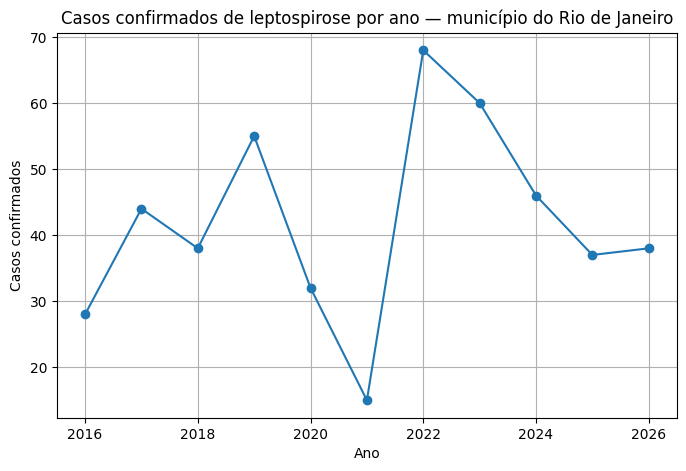

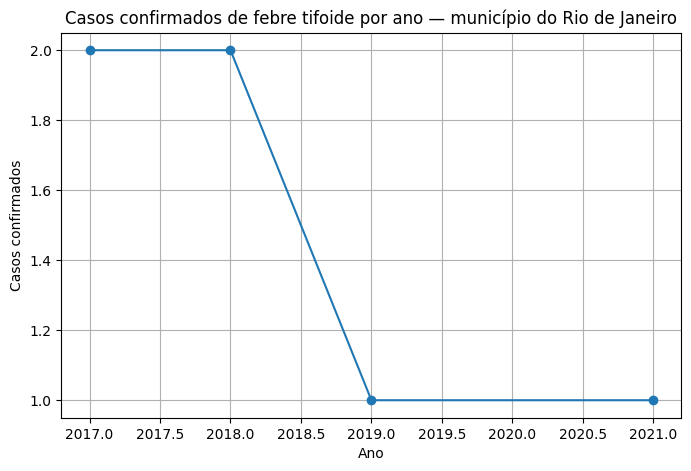

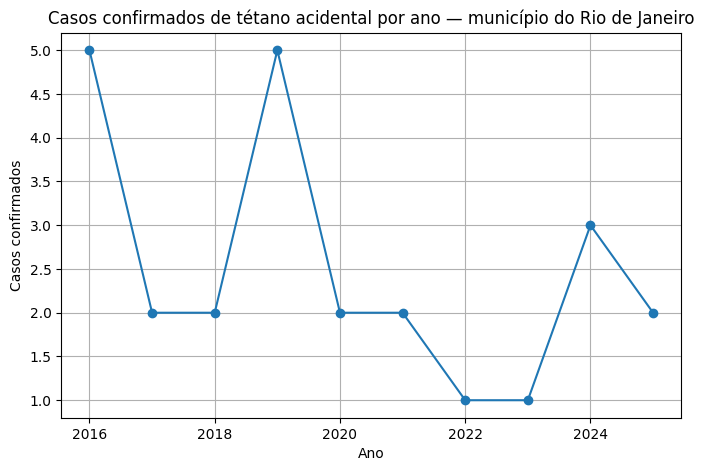

In [10]:
for df, nome in [(dados_leptospirose_rj, "leptospirose"), (dados_febre_tifoide_rj, "febre tifoide"), (dados_tetano_rj, "tétano acidental")]:
    p = df.select("Ano", "Total").orderBy("Ano").toPandas()
    plt.figure(figsize=(8,5))
    plt.plot(p["Ano"], p["Total"], marker="o")
    plt.title(f"Casos confirmados de {nome} por ano — município do Rio de Janeiro")
    plt.xlabel("Ano"); plt.ylabel("Casos confirmados"); plt.grid(True)
    plt.show()

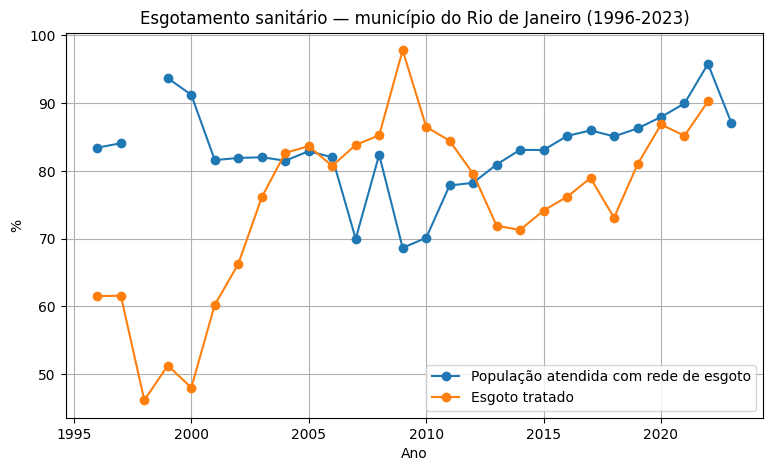

In [11]:
p = dados_esgoto_rj.orderBy("Ano").toPandas()
plt.figure(figsize=(9,5))
plt.plot(p["Ano"], p["Pct_populacao_atendida_esgoto"], marker="o", label="População atendida com rede de esgoto")
plt.plot(p["Ano"], p["Pct_esgoto_tratado"], marker="o", label="Esgoto tratado")
plt.title("Esgotamento sanitário — município do Rio de Janeiro (1996-2023)")
plt.xlabel("Ano"); plt.ylabel("%"); plt.legend(); plt.grid(True)
plt.show()

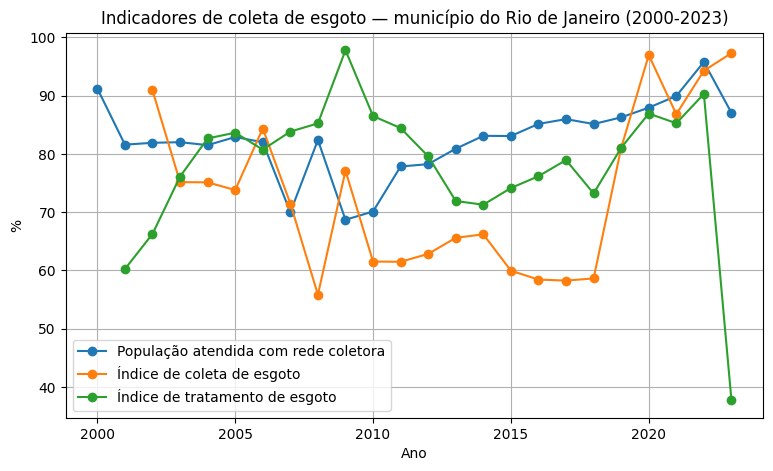

In [12]:
p = dados_indicadores_rj.orderBy("Ano").toPandas()
plt.figure(figsize=(9,5))
for c, rotulo in [("Pct_pop_atendida_rede_coletora", "População atendida com rede coletora"), ("Indice_coleta_esgoto", "Índice de coleta de esgoto"), ("Indice_tratamento_esgoto", "Índice de tratamento de esgoto")]:
    plt.plot(p["Ano"], p[c], marker="o", label=rotulo)
plt.title("Indicadores de coleta de esgoto — município do Rio de Janeiro (2000-2023)")
plt.xlabel("Ano"); plt.ylabel("%"); plt.legend(); plt.grid(True)
plt.show()

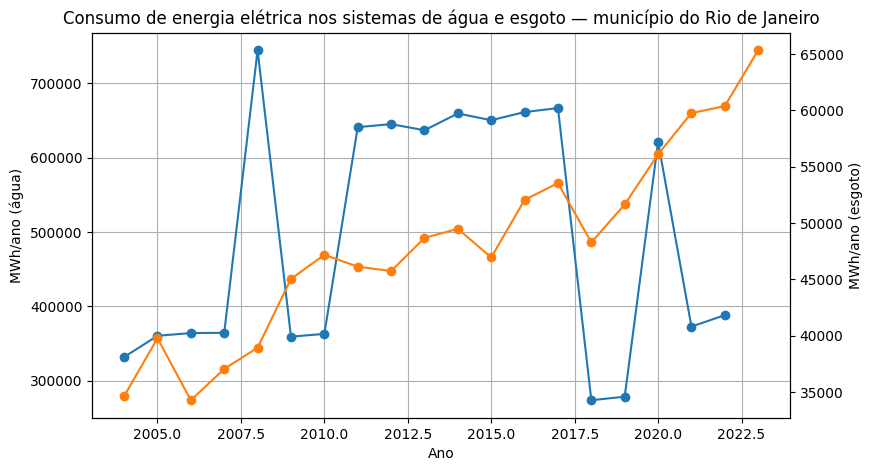

In [13]:
p = dados_energia_rj.orderBy("Ano").toPandas()
fig, eixo = plt.subplots(figsize=(9,5))
eixo.plot(p["Ano"], p["Energia_tratamento_agua_MWh"], marker="o", color="tab:blue", label="Tratamento de água")
eixo.set_ylabel("MWh/ano (água)")
eixo2 = eixo.twinx()
eixo2.plot(p["Ano"], p["Energia_tratamento_esgoto_MWh"], marker="o", color="tab:orange", label="Tratamento de esgoto")
eixo2.set_ylabel("MWh/ano (esgoto)")
plt.title("Consumo de energia elétrica nos sistemas de água e esgoto — município do Rio de Janeiro")
eixo.set_xlabel("Ano"); eixo.grid(True)
plt.show()